# EMQA_L4_supplier_month

**Since 2021 the normal 99% monthly limit was exceeded more often than expected**

Energy Markets Quantitative Analysis (EMQA), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L4/EMQA_L4_supplier_month/EMQA_L4_supplier_month.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, NullFormatter

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per zone / series


def legend_bottom(fig, ncol=4):
    # one legend for the whole figure, centred under the axes
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(key, value):
    # prints a number shown on the slide, under its key in lectures/L4/L4_numbers.json
    print(f'{key:<28} = {value}')


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')

In [3]:
END = pd.Timestamp('2026-10-31')     # cut-off of Lecture 4
# hourly day-ahead prices of Romania (15-min prices averaged to the hour from October 2025) and hourly national load
HP = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', usecols=['timestamp_utc', 'RO'], parse_dates=['timestamp_utc']).set_index('timestamp_utc')['RO']
GL = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', usecols=['timestamp_utc', 'load'], parse_dates=['timestamp_utc']).set_index('timestamp_utc')['load']
HP.index = pd.to_datetime(HP.index, utc=True)
GL.index = pd.to_datetime(GL.index, utc=True)
hl = pd.DataFrame({'p': HP, 'l': GL}).dropna()
hl['m'] = hl.index.tz_convert('Europe/Brussels').tz_localize(None).to_period('M')
print(len(hl), 'hours with both price and load')

103452 hours with both price and load


## A supplier's monthly cost overrun

Load-weighted price $\bar P^{L}_m=\sum_h P_hL_h/\sum_h L_h$; cost overrun $o_m=\bar P^{L}_m/\bar P^{L}_{m-1}-1$. The limit is $\hat\mu+\Phi^{-1}(0.99)\,\hat\sigma$ from the months up to December 2020.

In [4]:
mon = hl.groupby('m').apply(lambda g: pd.Series({'lwp': (g.p * g.l).sum() / g.l.sum(), 'hours': len(g)}))
mon = mon[(mon.index >= pd.Period('2015-02', 'M')) & (mon.index <= pd.Period(END, 'M'))]
mon['o'] = mon['lwp'] / mon['lwp'].shift(1) - 1
mon = mon.dropna()
o_pre = mon['o'][mon.index <= pd.Period('2020-12', 'M')]
lim_o = o_pre.mean() + stats.norm.ppf(0.99) * o_pre.std()
post = mon[mon.index >= pd.Period('2021-01', 'M')]
print('months', mon.index[0], 'to', mon.index[-1])
show('supplier.lim99', round(100 * lim_o, 1))
show('supplier.exc99_post', int((post['o'] > lim_o).sum()))
show('supplier.exp99_post', round(0.01 * len(post), 2))
show('supplier.worst', str(mon['o'].idxmax()))
show('supplier.worst_pct', round(100 * mon['o'].max(), 1))

months 2015-03 to 2026-10
supplier.lim99               = 50.5
supplier.exc99_post          = 3
supplier.exp99_post          = 0.7
supplier.worst               = 2024-11
supplier.worst_pct           = 86.6


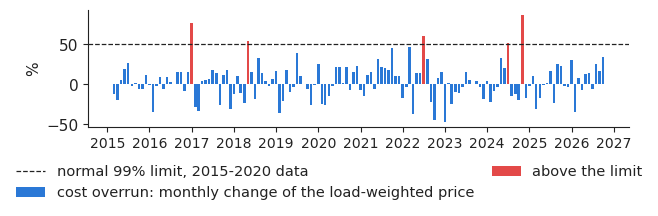

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 2.2))
xm = mon.index.to_timestamp()
above = (mon['o'] > lim_o).values
ax.bar(xm[~above], 100 * mon['o'][~above], width=22, color=PAL['RO'], label='cost overrun: monthly change of the load-weighted price')
ax.bar(xm[above], 100 * mon['o'][above], width=22, color=PAL['c8'], label='above the limit')
ax.axhline(100 * lim_o, color='#222222', lw=0.9, ls='--', label='normal 99% limit, 2015-2020 data')
ax.set_ylabel('%')
ax.tick_params(axis='x', labelsize=10)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
legend_bottom(fig, ncol=2)
fig.canvas.draw()
legend_top = max(lg.get_window_extent().y1 for lg in fig.legends) / fig.dpi
fig.tight_layout(rect=(0, max(legend_top - 0.08, 0.05) / fig.get_figheight(), 1, 1))
plt.savefig('supplier_month.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()